In [2]:
import requests
import json
import matplotlib.pyplot as plt

In [3]:
# 동영상 ID
video_id = "RvSg6kOPKKU"

get url!!!
get url finished!!!!!


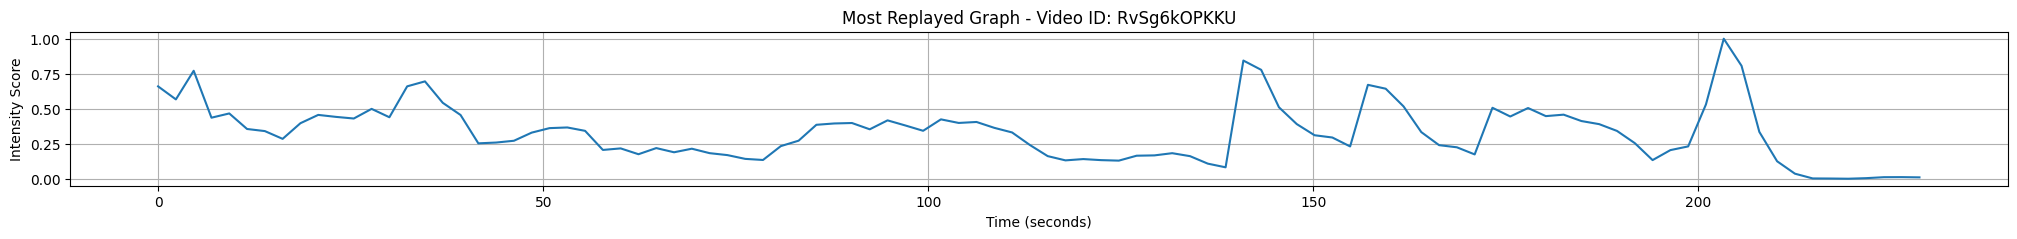

In [4]:
# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

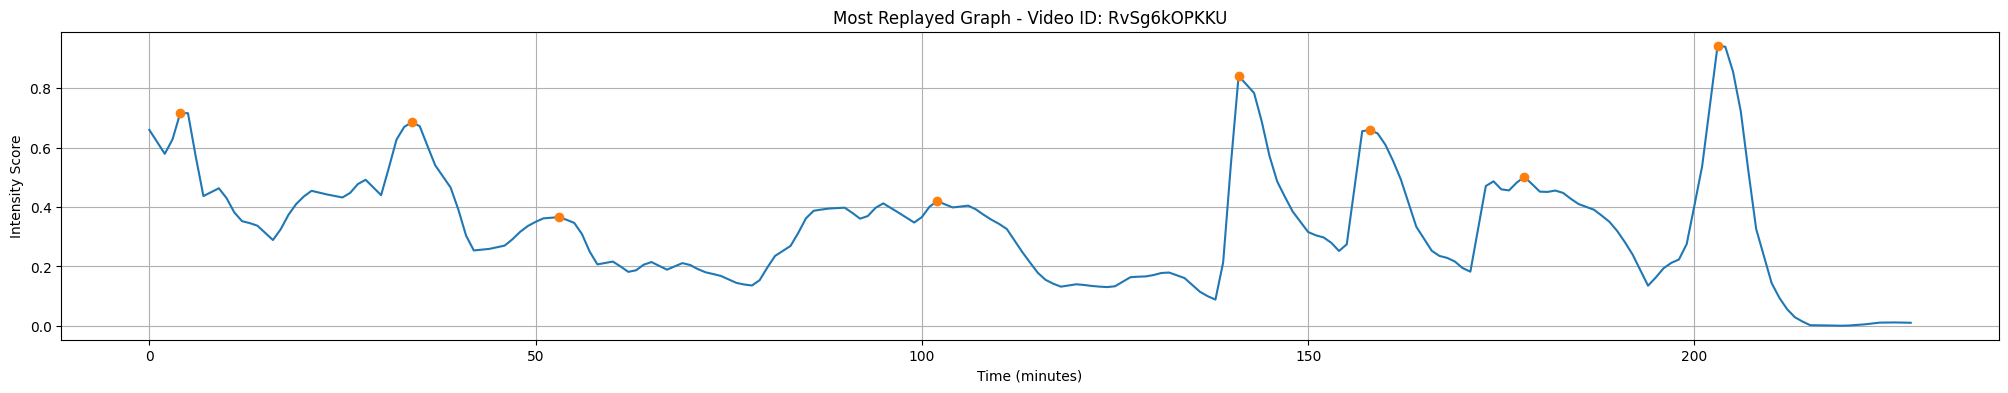

In [5]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [6]:
scores = smoothed_intensity_scores # 끝 점 무시해야하는줄 알았으나 자동으로 돼서 - 1 안함
total_time = 50
min_time = 3

In [7]:
len(smoothed_intensity_scores)

229

In [8]:
len(scores)

228

In [9]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score # reward
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [10]:
max_t = total_time
#  max_t + 1  => j 는 현재 설정 시간이라서 +1 을 해야 한다. 

In [11]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [12]:
len(states)

228

In [13]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + t < n: # 현재 위치 + 걸린 시간 => 총 길이 넘으면 안됨
                if i + 1 < n and t + 1 <= max_t :
                    states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
                if t >= min_time:
                    for j in range(i + 2, n):
                        states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [14]:
set_next_states(states, min_time, max_t)

In [15]:
states[206][5].next_states

[(207, 6),
 (208, 0),
 (209, 0),
 (210, 0),
 (211, 0),
 (212, 0),
 (213, 0),
 (214, 0),
 (215, 0),
 (216, 0),
 (217, 0),
 (218, 0),
 (219, 0),
 (220, 0),
 (221, 0),
 (222, 0),
 (223, 0),
 (224, 0),
 (225, 0),
 (226, 0),
 (227, 0)]

In [16]:
import pdb

def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    num_points = num_points + 1
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                for next_i, next_t in states[i][t].next_states:
                    # if i == 162 and t == 7 and k == num_points:
                    #     pdb.set_trace()  
                    if next_i < n and next_t <= max_t:
                        new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                        if new_score > dp[next_i, next_t, k]:
                            dp[next_i, next_t, k] = new_score
                            trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace



In [17]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [18]:
def find_path(states, dp, trace, num_points=30):

    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1)
    for i in range(n):
        if dp[i, 0, num_points + 1] > max_score:
            max_score = dp[i, 0, num_points + 1]
            max_index = (i, 0)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points + 1 
    while max_index != (-1, -1) and k > 0:
        current = (max_index[0], max_index[1], trace[max_index[0], max_index[1], k][0], trace[max_index[0], max_index[1], k][1])
        selected_points.append(current)  # (next_f, next_t, prev_f, prev_t) 형식으로 저장
        max_index = tuple(trace[max_index[0], max_index[1], k][:2])
        k -= 1
    
    selected_points.reverse()
    selected_points  = selected_points[:-1]

    return selected_points, max_score

In [19]:
dp, trace = DP(states, num_points=total_time) 

In [20]:
selected_tuple, max_score = find_path(states, dp, trace, num_points=total_time)


In [21]:
max_score

30.028177957480352

In [22]:
selected_tuple

[(1, 1, 0, 0),
 (2, 2, 1, 1),
 (3, 3, 2, 2),
 (4, 4, 3, 3),
 (5, 5, 4, 4),
 (6, 6, 5, 5),
 (26, 0, 6, 6),
 (27, 1, 26, 0),
 (28, 2, 27, 1),
 (29, 3, 28, 2),
 (31, 0, 29, 3),
 (32, 1, 31, 0),
 (33, 2, 32, 1),
 (34, 3, 33, 2),
 (35, 4, 34, 3),
 (36, 5, 35, 4),
 (37, 6, 36, 5),
 (38, 7, 37, 6),
 (39, 8, 38, 7),
 (140, 0, 39, 8),
 (141, 1, 140, 0),
 (142, 2, 141, 1),
 (143, 3, 142, 2),
 (144, 4, 143, 3),
 (145, 5, 144, 4),
 (146, 6, 145, 5),
 (156, 0, 146, 6),
 (157, 1, 156, 0),
 (158, 2, 157, 1),
 (159, 3, 158, 2),
 (160, 4, 159, 3),
 (161, 5, 160, 4),
 (162, 6, 161, 5),
 (173, 0, 162, 6),
 (174, 1, 173, 0),
 (175, 2, 174, 1),
 (176, 3, 175, 2),
 (177, 4, 176, 3),
 (178, 5, 177, 4),
 (179, 6, 178, 5),
 (180, 7, 179, 6),
 (181, 8, 180, 7),
 (182, 9, 181, 8),
 (183, 10, 182, 9),
 (201, 0, 183, 10),
 (202, 1, 201, 0),
 (203, 2, 202, 1),
 (204, 3, 203, 2),
 (205, 4, 204, 3),
 (206, 5, 205, 4)]

In [24]:

selected_smoothed_tuple = [scores[i] for i, _, _ , _ in selected_tuple]

In [25]:
selected_points =  [i for i, _, _ , _ in selected_tuple]
selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [26]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

In [27]:
# grouped_points = grouped_points[:-1]

In [32]:
grouped_points

[[1, 2, 3, 4, 5, 6],
 [26, 27, 28, 29],
 [31, 32, 33, 34, 35, 36, 37, 38, 39],
 [140, 141, 142, 143, 144, 145, 146],
 [156, 157, 158, 159, 160, 161, 162],
 [173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183],
 [201, 202, 203, 204, 205, 206]]

In [36]:
for group in grouped_points:
    group.append(group[-1]+1)


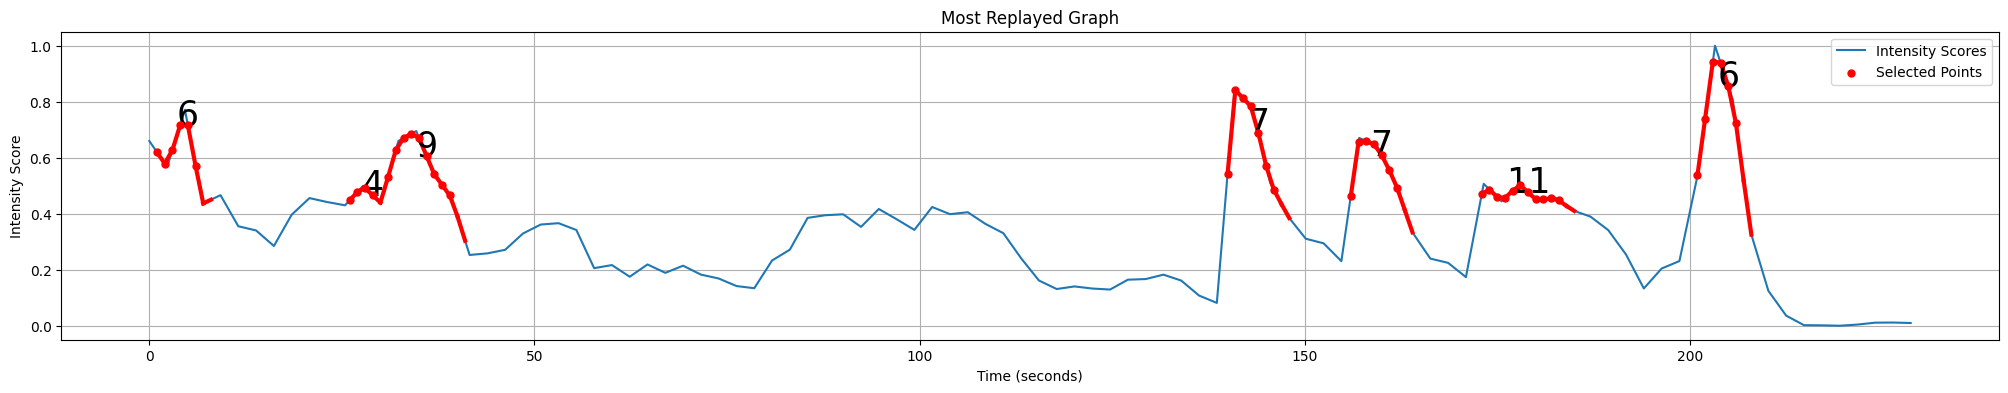

In [40]:

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(start_seconds, intensity_scores, label='Intensity Scores')
plt.scatter(selected_points, selected_smoothed_scores, color='r', label='Selected Points', s=25, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
for group, size in zip(grouped_points, group_sizes):
    mid_point = group[len(group) // 2]
    plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=25, ha='center')
# 그룹 내부의 점들 간 선 연결
for group in grouped_points:
    for i in range(len(group) -1 ):
        plt.plot([group[i], group[i + 1]], [smoothed_intensity_scores[group[i]], smoothed_intensity_scores[group[i + 1]]], color='r', linewidth=3)

plt.title('Most Replayed Graph')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()